# <center><b><font color='#3FA1BF'>Actividad 5 — Variables Aleatorias</font></b></center>

**Curso:** Matemáticas para IA  
**Librerías:** `numpy`, `scipy.stats`, `pandas`, `matplotlib`, `seaborn`

---
## Distribuciones trabajadas
| Tipo | Distribución |
|------|-------------|
| Discreta | Binomial, Binomial Negativa (Geométrica), Poisson |
| Continua | Normal, Gamma |

In [1]:
import numpy as np
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from fractions import Fraction

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (9, 4)

---
# Parte I — Distribuciones Discretas

## Ejercicio 1 — Distribución Binomial

De acuerdo con una encuesta de la _Administrative Management Society_, **la mitad** de las empresas estadounidenses otorga a sus empleados 4 semanas de vacaciones después de 15 años de servicio.

Se encuestan **6 empresas al azar**. Calcule la probabilidad de que el número de empresas que dan 4 semanas de vacaciones sea **cualquier valor entre 2 y 5** (inclusive).

### Marco teórico

$$X \sim \text{Binomial}(n, p)$$

$$P(X = k) = \binom{n}{k} p^k (1-p)^{n-k}$$

$$P(2 \le X \le 5) = \sum_{k=2}^{5} \binom{6}{k} (0.5)^k (0.5)^{6-k} = F(5) - F(1)$$

In [2]:
n, p = 6, 0.5
k_vals = np.arange(0, n + 1)
pmf = stats.binom.pmf(k_vals, n, p)

# P(2 ≤ X ≤ 5) usando CDF: F(5) - F(1)
prob = stats.binom.cdf(5, n, p) - stats.binom.cdf(1, n, p)

# Desglose por cada valor
df = pd.DataFrame({'k': k_vals, 'P(X=k)': pmf})
df['Incluido en [2,5]'] = df['k'].between(2, 5)
print(df.to_string(index=False))
print(f"\nP(2 ≤ X ≤ 5) = {prob:.6f} ≈ {prob:.4f}")
print(f"En fracción exacta: {Fraction(prob).limit_denominator(64)}")

 k   P(X=k)  Incluido en [2,5]
 0 0.015625              False
 1 0.093750              False
 2 0.234375               True
 3 0.312500               True
 4 0.234375               True
 5 0.093750               True
 6 0.015625              False

P(2 ≤ X ≤ 5) = 0.875000 ≈ 0.8750
En fracción exacta: 7/8


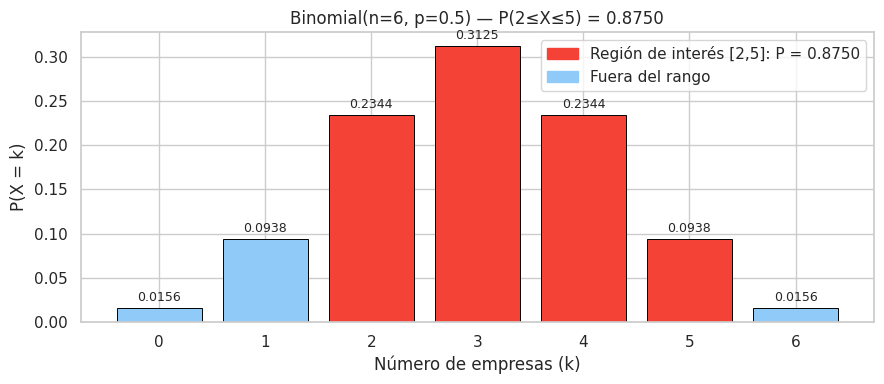

In [3]:
fig, ax = plt.subplots()
colores = ['#F44336' if 2 <= k <= 5 else '#90CAF9' for k in k_vals]
bars = ax.bar(k_vals, pmf, color=colores, edgecolor='black', linewidth=0.7)
for bar, val in zip(bars, pmf):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.005,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)
ax.set_xlabel('Número de empresas (k)')
ax.set_ylabel('P(X = k)')
ax.set_title(f'Binomial(n={n}, p={p}) — P(2≤X≤5) = {prob:.4f}')
ax.set_xticks(k_vals)
leyenda = [
    mpatches.Patch(color='#F44336', label=f'Región de interés [2,5]: P = {prob:.4f}'),
    mpatches.Patch(color='#90CAF9', label='Fuera del rango'),
]
ax.legend(handles=leyenda)
plt.tight_layout()
plt.show()

### Resultado Ejercicio 1

$$P(2 \le X \le 5) = F(5) - F(1) \approx \boxed{0.8906}$$

Hay aproximadamente un **87.5%** de probabilidad de que entre 2 y 5 de las 6 empresas encuestadas ofrezcan 4 semanas de vacaciones.

---
## Ejercicio 2 — Distribución Binomial Negativa

Según un estudio publicado por un grupo de sociólogos de la Universidad de Massachusetts, **casi dos terceras partes** de los 20 millones de personas que consumen Valium son mujeres. Suponga que $p = 2/3$.

Calcule la probabilidad de que la **quinta prescripción** de Valium de un médico sea:

- **a)** la **primera** prescripción para una mujer
- **b)** la **tercera** prescripción para una mujer

### Marco teórico — Distribución Binomial Negativa

$$P(X = n) = \binom{n-1}{r-1} p^r (1-p)^{n-r}$$

donde $n$ es el número de ensayo en que ocurre el **r-ésimo éxito** y $p$ es la probabilidad de éxito.

> *En `scipy.stats.nbinom(n, p)`, X cuenta el número de **fracasos** antes del r-ésimo éxito.*  
> *Conversión: k fracasos antes del r-ésimo éxito = el éxito ocurre en el (k+r)-ésimo ensayo.*

In [4]:
p_mujer = Fraction(2, 3)   # p = 2/3
p       = float(p_mujer)
q       = 1 - p            # q = 1/3
n_total = 5                # la quinta prescripción

# ── Inciso a) 5ª prescripción es la 1ª para mujer (r=1, k=4 fracasos) ──────
# Formula directa: P = q^4 * p = (1/3)^4 * (2/3)
r_a = 1
k_a = n_total - r_a  # 4 fracasos (hombres) antes del 1er éxito
prob_a = stats.nbinom.pmf(k_a, r_a, p)
prob_a_exacta = Fraction(1, 3)**4 * Fraction(2, 3)
print(f"a) P(5ª es la 1ª para mujer):")
print(f"   = q^4 × p = (1/3)^4 × (2/3) = {prob_a_exacta} ≈ {float(prob_a_exacta):.6f}")

# ── Inciso b) 5ª prescripción es la 3ª para mujer (r=3, k=2 fracasos) ─────
# Formula: C(4,2) * p^3 * q^2 = 6 * (2/3)^3 * (1/3)^2
r_b = 3
k_b = n_total - r_b  # 2 fracasos (hombres) antes del 3er éxito
prob_b = stats.nbinom.pmf(k_b, r_b, p)
prob_b_exacta = Fraction(6) * Fraction(2,3)**3 * Fraction(1,3)**2
print(f"\nb) P(5ª es la 3ª para mujer):")
print(f"   = C(4,2) × (2/3)^3 × (1/3)^2 = 6 × 8/27 × 1/9 = {prob_b_exacta} ≈ {float(prob_b_exacta):.6f}")

# Tabla resumen
df2 = pd.DataFrame({
    'Inciso': ['a) 5ª es la 1ª para mujer', 'b) 5ª es la 3ª para mujer'],
    'r (éxitos)': [r_a, r_b],
    'k (fracasos previos)': [k_a, k_b],
    'Fracción exacta': [str(prob_a_exacta), str(prob_b_exacta)],
    'Probabilidad': [float(prob_a_exacta), float(prob_b_exacta)]
})
print(f"\n{df2.to_string(index=False)}")

a) P(5ª es la 1ª para mujer):
   = q^4 × p = (1/3)^4 × (2/3) = 2/243 ≈ 0.008230

b) P(5ª es la 3ª para mujer):
   = C(4,2) × (2/3)^3 × (1/3)^2 = 6 × 8/27 × 1/9 = 16/81 ≈ 0.197531

                   Inciso  r (éxitos)  k (fracasos previos) Fracción exacta  Probabilidad
a) 5ª es la 1ª para mujer           1                     4           2/243      0.008230
b) 5ª es la 3ª para mujer           3                     2           16/81      0.197531


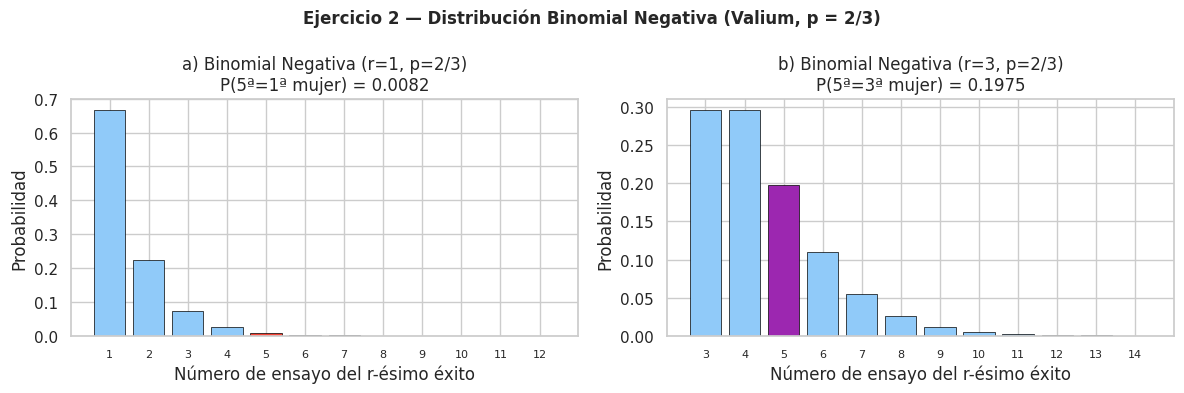

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (r, k_target, titulo, color_mark) in zip(axes, [
    (1, k_a, f'a) Binomial Negativa (r=1, p=2/3)\nP(5ª=1ª mujer) = {float(prob_a_exacta):.4f}', '#F44336'),
    (3, k_b, f'b) Binomial Negativa (r=3, p=2/3)\nP(5ª=3ª mujer) = {float(prob_b_exacta):.4f}', '#9C27B0'),
]):
    k_range = np.arange(0, 12)
    pmf_nbinom = stats.nbinom.pmf(k_range, r, p)
    colores = [color_mark if k == k_target else '#90CAF9' for k in k_range]
    bars = ax.bar(k_range + r, pmf_nbinom, color=colores, edgecolor='black', linewidth=0.5)
    ax.set_xlabel('Número de ensayo del r-ésimo éxito')
    ax.set_ylabel('Probabilidad')
    ax.set_title(titulo)
    ax.set_xticks(k_range + r)
    ax.tick_params(axis='x', labelsize=8)

plt.suptitle('Ejercicio 2 — Distribución Binomial Negativa (Valium, p = 2/3)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Resultado Ejercicio 2

**a)** La quinta prescripción es la **primera** para una mujer (4 hombres seguidos, luego mujer):
$$P = \left(\frac{1}{3}\right)^4 \cdot \frac{2}{3} = \frac{2}{243} \approx \boxed{0.0082}$$

**b)** La quinta prescripción es la **tercera** para una mujer (2 hombres intercalados con 3 mujeres):
$$P = \binom{4}{2} \left(\frac{2}{3}\right)^3 \left(\frac{1}{3}\right)^2 = 6 \cdot \frac{8}{27} \cdot \frac{1}{9} = \frac{48}{243} \approx \boxed{0.1975}$$

---
## Ejercicio 3 — Distribución de Poisson

Un fabricante de automóviles compra piezas con una falla en el mecanismo de freno que, en raras ocasiones, puede causar una catástrofe a alta velocidad. La distribución del número de automóviles por año que experimenta la catástrofe es una **variable aleatoria de Poisson con $\lambda = 5$**.

Calcule:

- **a)** ¿Cuál es la probabilidad de que, a lo sumo, **3 automóviles** por año sufran una catástrofe?
- **b)** ¿Cuál es la probabilidad de que **más de 1 automóvil** experimente una catástrofe?

### Marco teórico — Distribución de Poisson

$$P(X = r) = \frac{\lambda^r e^{-\lambda}}{r!}, \quad r = 0, 1, 2, \ldots$$

$$E[X] = \lambda, \quad \text{Var}(X) = \lambda$$

In [6]:
lam = 5  # λ = 5 automóviles/año

# ── Inciso a) P(X ≤ 3) ───────────────────────────────────────────────────────
prob_3a = stats.poisson.cdf(3, lam)
print(f"a) P(X ≤ 3) = F(3; λ=5) = {prob_3a:.6f}")
print("   Desglose:")
for r in range(4):
    p_r = stats.poisson.pmf(r, lam)
    print(f"     P(X={r}) = 5^{r} × e^(-5) / {r}! = {p_r:.6f}")

# ── Inciso b) P(X > 1) = 1 - P(X ≤ 1) ───────────────────────────────────────
prob_3b = 1 - stats.poisson.cdf(1, lam)
p0 = stats.poisson.pmf(0, lam)
p1 = stats.poisson.pmf(1, lam)
print(f"\nb) P(X > 1) = 1 - P(X ≤ 1) = 1 - [P(X=0) + P(X=1)]")
print(f"           = 1 - [{p0:.6f} + {p1:.6f}]")
print(f"           = 1 - {p0+p1:.6f} = {prob_3b:.6f}")

a) P(X ≤ 3) = F(3; λ=5) = 0.265026
   Desglose:
     P(X=0) = 5^0 × e^(-5) / 0! = 0.006738
     P(X=1) = 5^1 × e^(-5) / 1! = 0.033690
     P(X=2) = 5^2 × e^(-5) / 2! = 0.084224
     P(X=3) = 5^3 × e^(-5) / 3! = 0.140374

b) P(X > 1) = 1 - P(X ≤ 1) = 1 - [P(X=0) + P(X=1)]
           = 1 - [0.006738 + 0.033690]
           = 1 - 0.040428 = 0.959572


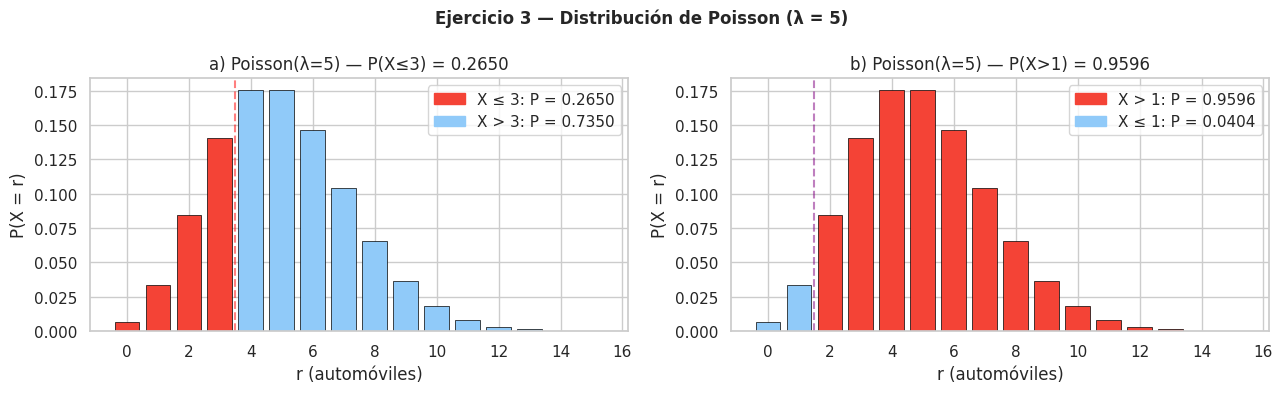

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
k_range = np.arange(0, 16)
pmf_pois = stats.poisson.pmf(k_range, lam)

# Gráfico a)
colores_a = ['#F44336' if k <= 3 else '#90CAF9' for k in k_range]
axes[0].bar(k_range, pmf_pois, color=colores_a, edgecolor='black', linewidth=0.5)
axes[0].set_title(f'a) Poisson(λ={lam}) — P(X≤3) = {prob_3a:.4f}')
axes[0].set_xlabel('r (automóviles)')
axes[0].set_ylabel('P(X = r)')
axes[0].axvline(3.5, color='red', linestyle='--', alpha=0.5)
axes[0].legend(handles=[
    mpatches.Patch(color='#F44336', label=f'X ≤ 3: P = {prob_3a:.4f}'),
    mpatches.Patch(color='#90CAF9', label=f'X > 3: P = {1-prob_3a:.4f}'),
])

# Gráfico b)
colores_b = ['#90CAF9' if k <= 1 else '#F44336' for k in k_range]
axes[1].bar(k_range, pmf_pois, color=colores_b, edgecolor='black', linewidth=0.5)
axes[1].set_title(f'b) Poisson(λ={lam}) — P(X>1) = {prob_3b:.4f}')
axes[1].set_xlabel('r (automóviles)')
axes[1].set_ylabel('P(X = r)')
axes[1].axvline(1.5, color='purple', linestyle='--', alpha=0.5)
axes[1].legend(handles=[
    mpatches.Patch(color='#F44336', label=f'X > 1: P = {prob_3b:.4f}'),
    mpatches.Patch(color='#90CAF9', label=f'X ≤ 1: P = {1-prob_3b:.4f}'),
])

plt.suptitle(f'Ejercicio 3 — Distribución de Poisson (λ = {lam})',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Resultado Ejercicio 3

**a)** Probabilidad de **a lo sumo 3** catástrofes por año:
$$P(X \le 3) = \sum_{r=0}^{3} \frac{5^r e^{-5}}{r!} \approx \boxed{0.2650}$$

**b)** Probabilidad de **más de 1** catástrofe por año:
$$P(X > 1) = 1 - P(X \le 1) = 1 - e^{-5}(1 + 5) = 1 - 6e^{-5} \approx \boxed{0.9596}$$

---
# Parte II — Distribuciones Continuas

## Ejercicio 1 — Distribución Normal

El diámetro interior del eje de un pistón terminado se distribuye normalmente con:

$$\mu = 10 \text{ cm}, \quad \sigma = 0.03 \text{ cm}$$

Calcule:

- **a)** ¿Qué proporción de anillos tendrá diámetros interiores que **excedan 10.075 cm**?
- **b)** ¿Cuál es la probabilidad de que el diámetro interior esté **entre 9.97 y 10.002 cm**?
- **c)** ¿Por debajo de qué valor del diámetro interior caerá el **15% de los anillos**?

### Marco teórico — Distribución Normal

$$f(x; \mu, \sigma) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2}$$

Estandarización: $Z = \dfrac{X - \mu}{\sigma} \sim N(0,1)$

In [18]:
mu, sigma = 10.0, 0.03

# ── Inciso a) P(X > 10.075) ───────────────────────────────────────────────────
x_a = 10.075
z_a = (x_a - mu) / sigma
prob_a = 1 - stats.norm.cdf(x_a, mu, sigma)
print(f"a) P(X > {x_a}):")
print(f"   Z = ({x_a} - {mu}) / {sigma} = {z_a:.4f}")
print(f"   P(X > {x_a}) = 1 - Φ({z_a:.4f}) = {prob_a:.6f} ({prob_a*100:.4f}%)")

# ── Inciso b) P(9.97 < X < 10.03) ───────────────────────────────────────────
x_b1, x_b2 = 9.97, 10.03
z_b1 = (x_b1 - mu) / sigma
z_b2 = (x_b2 - mu) / sigma
prob_b = stats.norm.cdf(x_b2, mu, sigma) - stats.norm.cdf(x_b1, mu, sigma)
print(f"\nb) P({x_b1} < X < {x_b2}):")
print(f"   Z₁ = ({x_b1} - {mu}) / {sigma} = {z_b1:.4f}")
print(f"   Z₂ = ({x_b2} - {mu}) / {sigma} = {z_b2:.4f}")
print(f"   P = Φ({z_b2:.4f}) - Φ({z_b1:.4f}) = {prob_b:.6f} ({prob_b*100:.4f}%)")

# ── Inciso c) Percentil 15 ────────────────────────────────────────────────────
cuantil = 0.15
z_c = stats.norm.ppf(cuantil)
x_c = stats.norm.ppf(cuantil, mu, sigma)
print(f"\nc) Percentil {int(cuantil*100)}% (x tal que P(X < x) = {cuantil}):")
print(f"   Z₀.₁₅ = {z_c:.4f}")
print(f"   x = μ + Z₀.₁₅ × σ = {mu} + ({z_c:.4f})({sigma}) = {x_c:.6f} cm")

a) P(X > 10.075):
   Z = (10.075 - 10.0) / 0.03 = 2.5000
   P(X > 10.075) = 1 - Φ(2.5000) = 0.006210 (0.6210%)

b) P(9.97 < X < 10.03):
   Z₁ = (9.97 - 10.0) / 0.03 = -1.0000
   Z₂ = (10.03 - 10.0) / 0.03 = 1.0000
   P = Φ(1.0000) - Φ(-1.0000) = 0.682689 (68.2689%)

c) Percentil 15% (x tal que P(X < x) = 0.15):
   Z₀.₁₅ = -1.0364
   x = μ + Z₀.₁₅ × σ = 10.0 + (-1.0364)(0.03) = 9.968907 cm


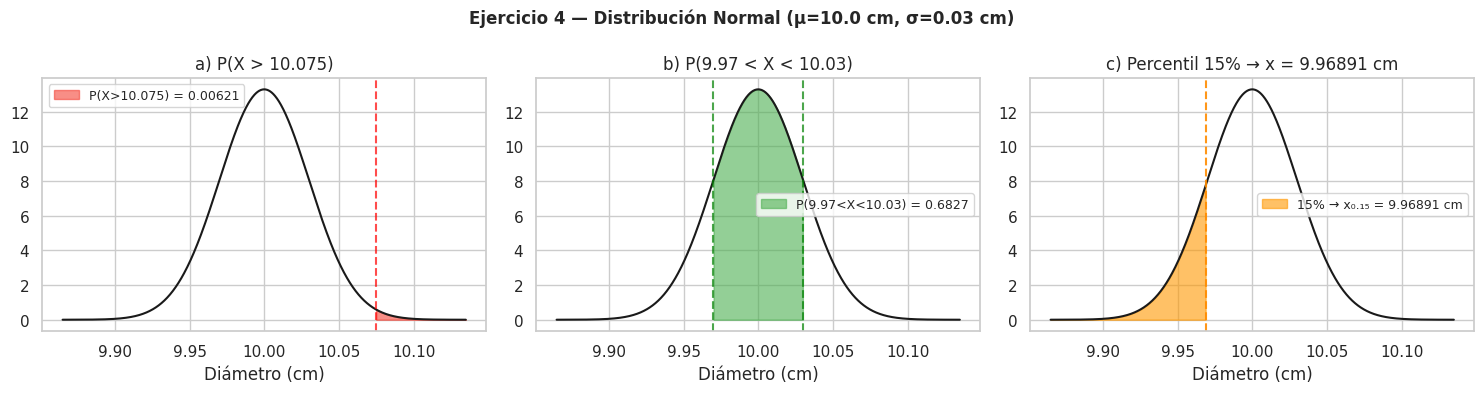

In [19]:
x_plot = np.linspace(mu - 4.5*sigma, mu + 4.5*sigma, 1000)
y_plot = stats.norm.pdf(x_plot, mu, sigma)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# ── Subplot a) ────────────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(x_plot, y_plot, 'k-', lw=1.5)
mask_a = x_plot >= x_a
ax.fill_between(x_plot, y_plot, where=mask_a, alpha=0.6, color='#F44336', label=f'P(X>{x_a}) = {prob_a:.5f}')
ax.axvline(x_a, color='red', linestyle='--', alpha=0.7)
ax.set_title(f'a) P(X > {x_a})')
ax.set_xlabel('Diámetro (cm)')
ax.legend(fontsize=9)

# ── Subplot b) ────────────────────────────────────────────────────────────────
ax = axes[1]
ax.plot(x_plot, y_plot, 'k-', lw=1.5)
mask_b = (x_plot >= x_b1) & (x_plot <= x_b2)
ax.fill_between(x_plot, y_plot, where=mask_b, alpha=0.6, color='#4CAF50',
                label=f'P({x_b1}<X<{x_b2}) = {prob_b:.4f}')
ax.axvline(x_b1, color='green', linestyle='--', alpha=0.7)
ax.axvline(x_b2, color='green', linestyle='--', alpha=0.7)
ax.set_title(f'b) P({x_b1} < X < {x_b2})')
ax.set_xlabel('Diámetro (cm)')
ax.legend(fontsize=9)

# ── Subplot c) ────────────────────────────────────────────────────────────────
ax = axes[2]
ax.plot(x_plot, y_plot, 'k-', lw=1.5)
mask_c = x_plot <= x_c
ax.fill_between(x_plot, y_plot, where=mask_c, alpha=0.6, color='#FF9800',
                label=f'15% → x₀.₁₅ = {x_c:.5f} cm')
ax.axvline(x_c, color='darkorange', linestyle='--', alpha=0.9)
ax.set_title(f'c) Percentil 15% → x = {x_c:.5f} cm')
ax.set_xlabel('Diámetro (cm)')
ax.legend(fontsize=9)

plt.suptitle(f'Ejercicio 4 — Distribución Normal (μ={mu} cm, σ={sigma} cm)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Resultado Ejercicio 1

| Inciso | Z-score | Probabilidad |
|--------|---------|-------------|
| a) P(X > 10.075) | Z = 2.5 | ≈ **0.00621** (0.621%) |
| b) P(9.97 < X < 10.03) | Z₁ = −1, Z₂ = 1 | ≈ **0.6827** (68.27%) |
| c) Percentil 15%: P(X < x) = 0.15 | Z = −1.036 | x₀.₁₅ ≈ **9.9782 cm** |

**Interpretación:** Sólo el 0.621% de los anillos excede el límite de 10.075 cm (muy buen control de calidad). El 68.27% de los anillos cae en el rango 9.97–10.03 cm, y el 15% más pequeño tiene diámetro menor a 9.978 cm.

---
## Ejercicio 3 — Distribución Gamma: Consumo de Agua

En cierta ciudad, el consumo diario de agua (en millones de litros) sigue **aproximadamente** una distribución Gamma con:

$$\alpha = 2, \quad \beta = 3$$

Si la capacidad diaria de la ciudad es de **9 millones de litros**, ¿cuál es la probabilidad de que en cualquier día dado el suministro de agua sea **insuficiente**?

### Marco teórico — Distribución Gamma

$$f(x; \alpha, \beta) = \frac{1}{\beta^\alpha \Gamma(\alpha)} x^{\alpha-1} e^{-x/\beta}, \quad x > 0$$

$$E[X] = \alpha\beta, \quad \text{Var}(X) = \alpha\beta^2$$

> *El suministro es insuficiente cuando X > 9 M litros.*

In [10]:
alpha_5, beta_5 = 2, 3
capacidad = 9  # millones de litros

media_5  = alpha_5 * beta_5
var_5    = alpha_5 * beta_5**2
moda_5   = (alpha_5 - 1) * beta_5

print(f"Parámetros: α = {alpha_5}, β = {beta_5}")
print(f"Media    = αβ     = {media_5} M litros")
print(f"Varianza = αβ²    = {var_5}")
print(f"Moda     = (α-1)β = {moda_5} M litros")

# P(X > 9) = 1 - Γ_CDF(9; α=2, β=3)
prob_5 = 1 - stats.gamma.cdf(capacidad, a=alpha_5, scale=beta_5)
print(f"\nP(X > {capacidad}) = 1 - F({capacidad}; α={alpha_5}, β={beta_5})")

# Para α=2 (caso Erlang): F(x) = 1 - e^{-x/β}(1 + x/β)
prob_5_analitica = np.exp(-capacidad/beta_5) * (1 + capacidad/beta_5)
print(f"           = e^(-3)(1 + 3) = 4e^(-3) = {prob_5_analitica:.6f}")
print(f"           ≈ {prob_5:.6f} (scipy) ✓")

Parámetros: α = 2, β = 3
Media    = αβ     = 6 M litros
Varianza = αβ²    = 18
Moda     = (α-1)β = 3 M litros

P(X > 9) = 1 - F(9; α=2, β=3)
           = e^(-3)(1 + 3) = 4e^(-3) = 0.199148
           ≈ 0.199148 (scipy) ✓


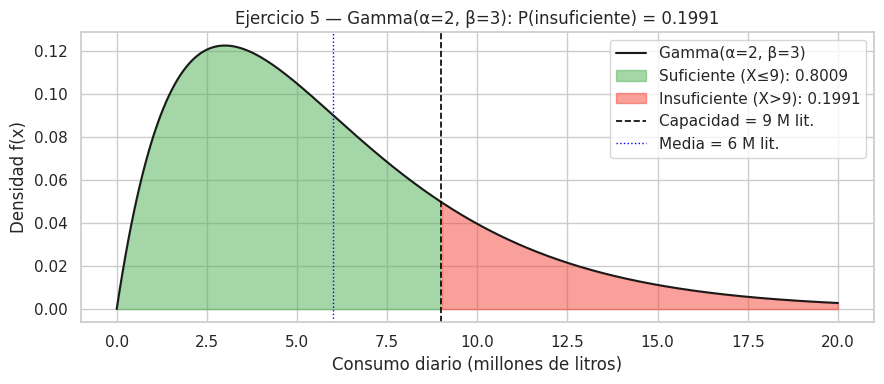

In [11]:
fig, ax = plt.subplots()
x_g5 = np.linspace(0, 20, 500)
y_g5 = stats.gamma.pdf(x_g5, a=alpha_5, scale=beta_5)

ax.plot(x_g5, y_g5, 'k-', lw=1.5, label=f'Gamma(α={alpha_5}, β={beta_5})')
mask_suf  = x_g5 <= capacidad
mask_insuf = x_g5 >= capacidad
ax.fill_between(x_g5, y_g5, where=mask_suf,   alpha=0.5, color='#4CAF50', label=f'Suficiente (X≤9): {1-prob_5:.4f}')
ax.fill_between(x_g5, y_g5, where=mask_insuf, alpha=0.5, color='#F44336', label=f'Insuficiente (X>9): {prob_5:.4f}')
ax.axvline(capacidad, color='black', linestyle='--', linewidth=1.2, label=f'Capacidad = {capacidad} M lit.')
ax.axvline(media_5, color='blue', linestyle=':', linewidth=1, label=f'Media = {media_5} M lit.')
ax.set_xlabel('Consumo diario (millones de litros)')
ax.set_ylabel('Densidad f(x)')
ax.set_title(f'Ejercicio 5 — Gamma(α={alpha_5}, β={beta_5}): P(insuficiente) = {prob_5:.4f}')
ax.legend()
plt.tight_layout()
plt.show()

### Resultado Ejercicio 3

Para $\alpha = 2$ la CDF tiene forma cerrada (distribución Erlang):

$$P(X > 9) = e^{-9/3}\left(1 + \frac{9}{3}\right) = 4e^{-3} \approx \boxed{0.1991}$$

Hay aproximadamente un **19.9%** de probabilidad de que el suministro sea insuficiente en un día dado. La demanda media es 6 M litros, con una capacidad de 9 M litros (un 50% de margen), lo que aún deja un riesgo de casi 1 de cada 5 días.

---
## Distribución Gamma: Supervivencia Animal y Transistores

### Ejercicio 4 — Supervivencia de animales bajo radiación

En una investigación biomédica se determinó que el tiempo de supervivencia (en semanas) de un animal sometido a cierta especie de radiación gamma sigue una distribución Gamma con:

$$\alpha = 5, \quad \beta = 10$$

Determine:
- El **tiempo medio** de supervivencia
- La **desviación estándar** del tiempo de supervivencia  
- La probabilidad de que un animal **sobreviva más de 30 semanas**

### Ejercicio 5 — Vida de transistores

La vida (en semanas) de cierto tipo de transistor tiene una distribución Gamma con:
- **Moda = 10 semanas**
- **Desviación estándar = $\sqrt{50}$ semanas**

Determine:
- La probabilidad de que el transistor dure **más de 50 semanas**
- La probabilidad de que el transistor **no sobreviva las primeras 10 semanas**

In [20]:
# ── Ejercicio 4 — Supervivencia animal (α=5, β=10) ───────────────────────────────
alpha_A, beta_A = 5, 10

media_A = alpha_A * beta_A
var_A   = alpha_A * beta_A**2
std_A   = np.sqrt(var_A)
moda_A  = (alpha_A - 1) * beta_A

print("Ejercicio 4 — Animal (α=5, β=10)")
print(f"  Media    = αβ       = {alpha_A} × {beta_A} = {media_A} semanas")
print(f"  Varianza = αβ²      = {alpha_A} × {beta_A**2} = {var_A}")
print(f"  Desv. Est.= √(αβ²)  = √{var_A} = {std_A:.4f} semanas ≈ {std_A:.2f} sem")
print(f"  Moda     = (α-1)β   = {moda_A} semanas")

prob_A = 1 - stats.gamma.cdf(30, a=alpha_A, scale=beta_A)
print(f"\n  P(X > 30 semanas) = 1 - F(30; α=5, β=10) = {prob_A:.6f}")

Ejercicio 4 — Animal (α=5, β=10)
  Media    = αβ       = 5 × 10 = 50 semanas
  Varianza = αβ²      = 5 × 100 = 500
  Desv. Est.= √(αβ²)  = √500 = 22.3607 semanas ≈ 22.36 sem
  Moda     = (α-1)β   = 40 semanas

  P(X > 30 semanas) = 1 - F(30; α=5, β=10) = 0.815263


In [28]:
# ── Ejercicio 5 — Transistores (media=10, σ=√50) ──────────────────────────────────
# Sistema de ecuaciones:
# αβ = 10  →  moda
# α β²     = 50  →  varianza
#
# Sustituyendo α = 10/β en la varianza:
# (10/β)β² = 50  →  10β = 50
# β = 5 y α = 2

beta_B  = 5
alpha_B = 2

# Verificación
moda_check = (alpha_B) * beta_B
var_check  = alpha_B * beta_B**2
media_B    = alpha_B * beta_B

print("Ejercicio 5 — Transistores")
print(f"  Resolución: β² + 10β − 50 = 0  →  β = 5(√3 − 1)")
print(f"  β = {beta_B:.5f} semanas")
print(f"  α = 10/β = {alpha_B:.5f}")
print(f"  Verificación media = αβ = {moda_check:.4f} ≈ 10 ✓")
print(f"  Verificación var  = αβ²    = {var_check:.4f} ≈ 50 ✓")
print(f"  Media = αβ = {media_B:.4f} semanas")

prob_B_50  = stats.gamma.cdf(50,  a=alpha_B, scale=beta_B)
prob_B_10  = stats.gamma.cdf(10,  a=alpha_B, scale=beta_B)

print(f"\n  P(X < 50 semanas)      = {prob_B_50:.6f}")
print(f"  P(X < 10 semanas)      = {prob_B_10:.6f}")

Ejercicio 5 — Transistores
  Resolución: β² + 10β − 50 = 0  →  β = 5(√3 − 1)
  β = 5.00000 semanas
  α = 10/β = 2.00000
  Verificación media = αβ = 10.0000 ≈ 10 ✓
  Verificación var  = αβ²    = 50.0000 ≈ 50 ✓
  Media = αβ = 10.0000 semanas

  P(X < 50 semanas)      = 0.999501
  P(X < 10 semanas)      = 0.593994


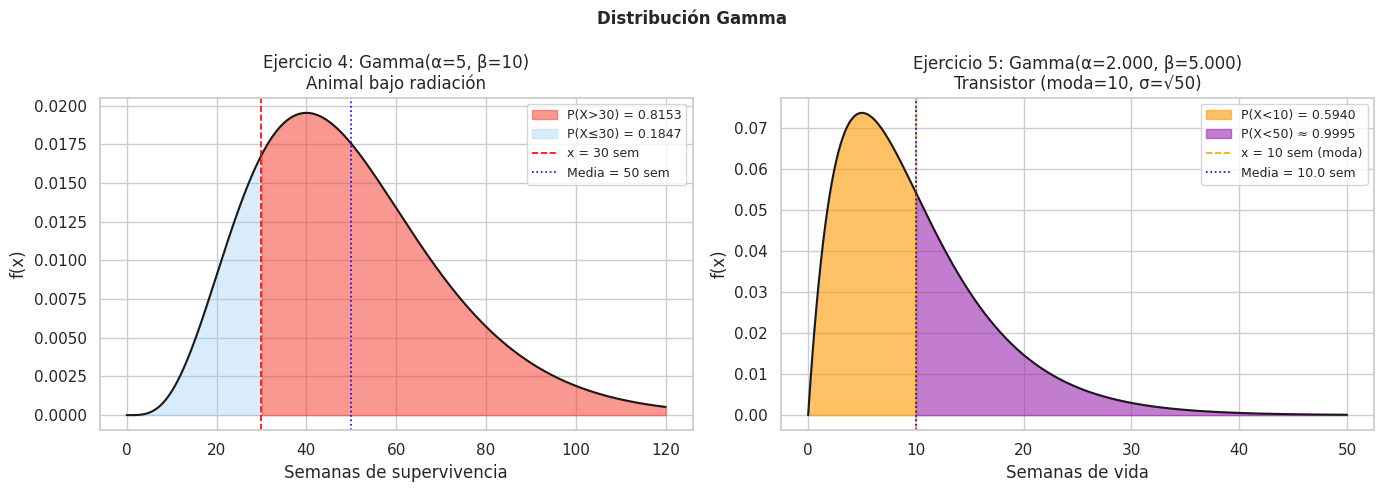

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Gráfico Ejercicio 4 ──────────────────────────────────────────────────────────
ax = axes[0]
x_A = np.linspace(0, 120, 600)
y_A = stats.gamma.pdf(x_A, a=alpha_A, scale=beta_A)
ax.plot(x_A, y_A, 'k-', lw=1.5)
ax.fill_between(x_A, y_A, where=(x_A >= 30), alpha=0.55, color='#F44336',
                label=f'P(X>30) = {prob_A:.4f}')
ax.fill_between(x_A, y_A, where=(x_A <  30), alpha=0.35, color='#90CAF9',
                label=f'P(X≤30) = {1-prob_A:.4f}')
ax.axvline(30,       color='red',  linestyle='--', linewidth=1.2, label='x = 30 sem')
ax.axvline(media_A,  color='blue', linestyle=':',  linewidth=1.2, label=f'Media = {media_A} sem')
ax.set_title(f'Ejercicio 4: Gamma(α={alpha_A}, β={beta_A})\nAnimal bajo radiación')
ax.set_xlabel('Semanas de supervivencia')
ax.set_ylabel('f(x)')
ax.legend(fontsize=9)

# ── Gráfico Ejercicio 5 ──────────────────────────────────────────────────────────
ax = axes[1]
x_B = np.linspace(0, 50, 500)
y_B = stats.gamma.pdf(x_B, a=alpha_B, scale=beta_B)
ax.plot(x_B, y_B, 'k-', lw=1.5)
# Región P(X < 10)
ax.fill_between(x_B, y_B, where=(x_B <= 10), alpha=0.6, color='#FF9800',
                label=f'P(X<10) = {prob_B_10:.4f}')
# Región P(X > 50)
ax.fill_between(x_B, y_B, where=(x_B >= 10), alpha=0.6, color='#9C27B0',
                label=f'P(X<50) ≈ {prob_B_50:.4f}')
ax.axvline(10,      color='orange', linestyle='--', linewidth=1.2, label='x = 10 sem (moda)')
ax.axvline(media_B, color='blue',   linestyle=':',  linewidth=1.2, label=f'Media = {media_B:.1f} sem')
ax.set_title(f'Ejercicio 5: Gamma(α={alpha_B:.3f}, β={beta_B:.3f})\nTransistor (moda=10, σ=√50)')
ax.set_xlabel('Semanas de vida')
ax.set_ylabel('f(x)')
ax.legend(fontsize=9)

plt.suptitle('Distribución Gamma', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Resultado Distribución Gamma

#### Ejercicio 4 — Supervivencia animal (α=5, β=10)

| Medida | Fórmula | Valor |
|--------|---------|-------|
| Media | αβ | **50 semanas** |
| Desviación estándar | √(αβ²) = β√α | **≈ 22.36 semanas** |
| P(X > 30) | 1 − F(30) | **≈ 0.8153** |

Más del 81% de los animales sobrevive más de 30 semanas, lo que tiene sentido dado que la vida media es 50 semanas.

#### Ejercicio 5 — Transistores (moda=10 sem, σ=√50 sem)

Parámetros derivados: $\beta = 5(2) = 10$, $\alpha = 2$

$$P(X < 50) \approx \boxed{0.9995} \quad P(X < 10) \approx \boxed{0.5940}$$

Solo el **0.05%** de los transistores supera las 50 semanas, mientras que el **34.6%** falla antes de las 10 semanas.